# Examen Segunda Convocatoria Franja Mañana

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Tienda Online

Adjunto al examen hay tres ficheros *CSV* que describen el funcionamiento de una tienda online.

- *clientes.csv*, describe la lista de clientes de la tienda
  - `id_cliente`, `nombre`, `ciudad`, `edad`, `fecha_alta`
- *productos.csv*, la lista de productos a la venta actualmente en la tienda
  - `id_producto`, `nombre_producto`, `categoria`, `precio`
- *pedidos.csv*, es el histórico de pedidos que los clientes han realizado en la tienda
  - `id_pedido`, `id_cliente`, `id_producto`, `cantidad`, `fecha_pedido`
 
Cada fichero/tabla tiene un campo (`id_xxxx`) que identifica de manera única a cada registro. Por tanto la tabla de pedidos, es una relación que combina el hecho de que un cliente `id_cliente` haya realizado un pedido en una `fecha_pedido` de una `cantidad` de un producto `id_producto`.

Algunos pedidos pueden hacer referencia a clientes o productos que *no existan* en los ficheros/tablas maestras de datos de clientes o productos. Pueden haberse producido bajas de clientes, productos descatalogados, errores de registro,...

## Criterios generales

- Código funcional que resuelve lo pedido, usando las librerías y métodos de manera correcta y óptima: puntuación completa del apartado.
- Código funcional que resuelve lo pedido, usando bucles o métodos iterativos poco eficientes: 50% del apartado.

## 01 - Exploración de los datos (2pt)

### 01.A (0.5pt)

Carga los tres ficheros en sus correspondientes *DataFrame*.

In [2]:
clientes = pd.read_csv('clientes.csv')
productos = pd.read_csv('productos.csv')
pedidos = pd.read_csv('pedidos.csv')

print(clientes.head())
print(productos.head())
print(pedidos.head())


   id_cliente          nombre    ciudad  edad  fecha_alta
0           1    Luis Vázquez   Sevilla    68  2023-07-09
1           2     Adrián Díaz    Murcia    67  2023-12-03
2           3       Laura Gil    Madrid    44  2023-10-28
3           4     Luis Torres    Murcia    19  2022-05-02
4           5  Elena Martínez  Zaragoza    49  2024-01-14
   id_producto    nombre_producto    categoria  precio
0            1     Auriculares BT  Electrónica   41.21
1            2     Cargador USB-C  Electrónica  234.35
2            3   Teclado mecánico  Electrónica  112.29
3            4  Ratón inalámbrico  Electrónica   98.91
4            5   Altavoz portátil  Electrónica  183.77
   id_pedido  id_cliente  id_producto  cantidad fecha_pedido
0          1           8           12       5.0   2025-06-13
1          2         141           16       3.0   2025-05-20
2          3         110           30       1.0   2024-04-08
3          4          46           25       1.0   2024-11-21
4          5     

### 01.B (0.5pt)

Muestra cuantos registros, los tipos de datos y el número de valores nulos por columna de las tres tablas.

In [3]:
for nombre, df in [('clientes', clientes), ('productos', productos), ('pedidos', pedidos)]:
    print(f"--- {nombre} ---")
    print(f"Registros: {len(df)}")
    print(df.dtypes)
    print(df.isnull().sum())
    print()


--- clientes ---
Registros: 150
id_cliente     int64
nombre        object
ciudad        object
edad           int64
fecha_alta    object
dtype: object
id_cliente    0
nombre        0
ciudad        0
edad          0
fecha_alta    0
dtype: int64

--- productos ---
Registros: 30
id_producto          int64
nombre_producto     object
categoria           object
precio             float64
dtype: object
id_producto        0
nombre_producto    0
categoria          0
precio             0
dtype: int64

--- pedidos ---
Registros: 900
id_pedido         int64
id_cliente        int64
id_producto       int64
cantidad        float64
fecha_pedido     object
dtype: object
id_pedido        0
id_cliente       0
id_producto      0
cantidad        21
fecha_pedido     0
dtype: int64



### 01.C (0.5pt)

- ¿Cuantos clientes distintos hay por ciudad?
- ¿Cuantos productos distintos hay por categoria?

In [4]:
clientes_por_ciudad = clientes.groupby('ciudad')['id_cliente'].nunique()
productos_por_categoria = productos.groupby('categoria')['id_producto'].nunique()

print(clientes_por_ciudad)
print(productos_por_categoria)


ciudad
Alicante     13
Barcelona    21
Bilbao        9
Madrid       15
Murcia       15
Málaga       10
Sevilla      17
Valencia     16
Vigo         20
Zaragoza     14
Name: id_cliente, dtype: int64
categoria
Deporte        6
Electrónica    6
Hogar          6
Libros         6
Ropa           6
Name: id_producto, dtype: int64


### 01.D (0.5pt)

Comprueba si hay algún cliente duplicado en la tabla de clientes (el campo *id_cliente* debería ser único en toda la tabla) y si hay algún producto duplicado en la tabla de productos.

In [5]:
clientes_duplicados = clientes['id_cliente'].duplicated().sum()
productos_duplicados = productos['id_producto'].duplicated().sum()

print("Clientes duplicados:", clientes_duplicados)
print("Productos duplicados:", productos_duplicados)


Clientes duplicados: 0
Productos duplicados: 0


## 02 - Merge / Join (3pt)

### 02.A (0.7pt)

Antes de unir las tablas, calcula cuántos pedidos tienen un *id_cliente* que no existe en la tabla de clientes, y cuántos pedidos tienen un *id_producto* que no existe en la tabla de productos.

In [6]:
pedidos_cliente_inexistente = (~pedidos['id_cliente'].isin(clientes['id_cliente'])).sum()
pedidos_producto_inexistente = (~pedidos['id_producto'].isin(productos['id_producto'])).sum()

print("Pedidos con id_cliente inexistente:", pedidos_cliente_inexistente)
print("Pedidos con id_producto inexistente:", pedidos_producto_inexistente)


Pedidos con id_cliente inexistente: 58
Pedidos con id_producto inexistente: 99


### 02.B (0.8pt)

Realiza un merge de la tabla de pedidos con la de clientes, usando el campo adecuado y un left join. Después comprueba cuántas filas del resultado tienen el campo `nombre` del cliente nulo (es decir, pedidos huerfanos de cliente) y verifica que coincide con el número calculado en el apartado anterior.

In [7]:
pedidos_clientes = pedidos.merge(clientes, on='id_cliente', how='left')
pedidos_huerfanos_cliente = pedidos_clientes['nombre'].isnull().sum()

print("Pedidos huerfanos de cliente:", pedidos_huerfanos_cliente)
print("Coincide con el apartado anterior:", pedidos_huerfanos_cliente == pedidos_cliente_inexistente)


Pedidos huerfanos de cliente: 58
Coincide con el apartado anterior: True


### 02.C (0.8pt)

Sobre el dataframe obtenido en el punto anterior, realiza un segundo merge con la tabla de productos, usando también un left join, para obtener una tabla completa con la información del cliente y producto en cada fila.

In [8]:
pedidos_completos = pedidos_clientes.merge(productos, on='id_producto', how='left')

print(pedidos_completos.head())


   id_pedido  id_cliente  id_producto  cantidad fecha_pedido         nombre  \
0          1           8           12       5.0   2025-06-13  Nuria Vázquez   
1          2         141           16       3.0   2025-05-20  Javier Moreno   
2          3         110           30       1.0   2024-04-08  Laura Serrano   
3          4          46           25       1.0   2024-11-21    Laura Ramos   
4          5         125           22       2.0   2024-02-27    Iván García   

     ciudad  edad  fecha_alta       nombre_producto categoria  precio  
0  Zaragoza  51.0  2023-04-08   Organizador armario     Hogar  180.85  
1      Vigo  60.0  2024-01-06  Chaqueta impermeable      Ropa  161.08  
2    Madrid  63.0  2023-02-24  Poesía contemporánea    Libros  249.27  
3  Valencia  39.0  2022-10-23      Novela histórica    Libros  113.37  
4    Bilbao  18.0  2023-12-09          Balón fútbol   Deporte  207.22  


### 02.D (0.7pt)

A partir de este último dataframe con los datos completos, crea una versión limpia que se llame *`pedidos_validos`* y contenga solo los pedidos con cliente y producto conocidos (sin nulos en el campo `nombre` ni en `nombre_producto`).

Verificar cuantos pedidos validos quedan finalmente.

Escribe una pequeña interpretación de porque se elige un left join en este caso y se filtra después, en lugar de hacer directamente un inner join. ¿Hay alguna ventaja en hacerlo en dos pasos?

In [9]:
pedidos_validos = pedidos_completos[pedidos_completos['nombre'].notnull() & pedidos_completos['nombre_producto'].notnull()].copy()

print("Pedidos validos:", len(pedidos_validos))


Pedidos validos: 749


El left join seguido de un filtrado permite conservar en un primer momento toda la información del histórico de pedidos, incluidos los que hacen referencia a clientes o productos inexistentes. Esto da la posibilidad de auditar esos casos (contarlos, revisar a qué fechas o IDs corresponden) antes de descartarlos, algo que un inner join directo no permite porque esas filas huérfanas desaparecen sin dejar rastro.

El punto clave es que separar la unión del filtrado convierte cada paso en una decisión explícita y verificable: primero se controla que el número de nulos generados por el merge coincida con el número de IDs inexistentes calculado de forma independiente (como se hizo en 02.A y 02.B), y solo después se decide filtrar. Con un inner join, ese control de calidad queda oculto dentro de la propia unión.

Dicho esto, el resultado final de datos (`pedidos_validos`) es el mismo con ambos enfoques cuando el filtro aplicado es equivalente a la condición del inner join. La ventaja de hacerlo en dos pasos no está en el resultado, sino en la trazabilidad del proceso: permite detectar errores de integridad referencial en los datos de origen antes de perder esa información.

## 03 - NumPy (2pt)

Para este punto usa siempre este último dataframe con todos los datos limpios *`pedidos_validos`*.

### 03.A (0.6pt)

Calcula la media, mediana y desviación standard de la columna `cantidad` usando solo funciones de NumPy. Puede haber datos nulos en esa columna, no deberías tenerlos en cuenta para estos cálculos.

In [10]:
media_cantidad = np.nanmean(pedidos_validos['cantidad'])
mediana_cantidad = np.nanmedian(pedidos_validos['cantidad'])
std_cantidad = np.nanstd(pedidos_validos['cantidad'])

print(media_cantidad, mediana_cantidad, std_cantidad)


2.9768076398362893 3.0 1.4222005746707276


### 03.B (0.7pt)

Crea una nueva columna llamada `importe` en el dataframe limpio que sea el resultado de multiplicar `cantidad` por `precio`, usando funciones de NumPy. Si la `cantidad` es nula, entonces `importe` debería quedara también nulo.

In [11]:
pedidos_validos['importe'] = np.multiply(pedidos_validos['cantidad'], pedidos_validos['precio'])

print(pedidos_validos[['cantidad', 'precio', 'importe']].head(10))


    cantidad  precio  importe
0        5.0  180.85   904.25
1        3.0  161.08   483.24
2        1.0  249.27   249.27
3        1.0  113.37   113.37
4        2.0  207.22   414.44
5        5.0  249.27  1246.35
6        1.0  207.22   207.22
7        5.0  238.04  1190.20
8        4.0  213.38   853.52
10       5.0   98.91   494.55


### 03.C (0.7pt)

En NumPy existe la función [`np.percentile`](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html) para calcular el percentil (el valor por debajo del cual se encuentra un determinado porcentaje de los datos). Usa esta función para calcular el umbral del 75% del importe de todos los pedidos. Puede haber datos nulos en la columna `importe`, no deberías tenerlos en cuenta para estos cálculos.

Crea una nueva columna llamada `tipo_pedido` en el dataframe limpio que contenga el string *"grande"* si el `importe` supera el percentil 75 de todos los importes, y *"normal"* en caso contrario.

In [12]:
percentil_75 = np.nanpercentile(pedidos_validos['importe'], 75)
pedidos_validos['tipo_pedido'] = np.where(pedidos_validos['importe'] > percentil_75, 'grande', 'normal')
pedidos_validos.loc[pedidos_validos['importe'].isnull(), 'tipo_pedido'] = np.nan

print(percentil_75)
print(pedidos_validos['tipo_pedido'].value_counts(dropna=False))


589.26
tipo_pedido
normal    550
grande    183
NaN        16
Name: count, dtype: int64


## 04 - Pandas (1.5pt)

Para este punto usa siempre el dataframe con todos los datos limpios *`pedidos_validos`*.

### 04.A (0.5pt)

¿Cuántos pedidos tienen `cantidad` nula? Decide una estrategia razonable para tratarlos (eliminarlos o rellenarlos de alguna manera), explica porqué y ejecuta la acción que decidas sobre el dataframe *`pedidos_validos`*.

In [13]:
pedidos_cantidad_nula = pedidos_validos['cantidad'].isnull().sum()
print("Pedidos con cantidad nula:", pedidos_cantidad_nula)

pedidos_validos = pedidos_validos.dropna(subset=['cantidad'])

print("Pedidos validos tras eliminar cantidad nula:", len(pedidos_validos))


Pedidos con cantidad nula: 16
Pedidos validos tras eliminar cantidad nula: 733


La estrategia elegida es eliminar los pedidos con `cantidad` nula, y no rellenarlos con un valor estimado. El punto clave es que `cantidad` es el dato de origen sobre el que se calcula `importe`: cualquier valor que se invente ahí (una media, una moda, un cero) se propaga directamente al análisis de ingresos y distorsiona magnitudes que en 03 ya se calcularon como reales.

Estos registros representan una fracción pequeña del total (16 pedidos sobre 749, poco más del 2%), por lo que eliminarlos no compromete la representatividad del resto del análisis. Conviene advertir que rellenar con la media, por ejemplo, generaría un `importe` ficticio que después contaminaría agregaciones como las de 04.B y 04.C sin que exista evidencia real de cuánto se pidió en esos casos.

### 04.B (0.5pt)

Agrupa por el campo `categoría` y calcula el importe total (`sum`) y el número de pedidos (`count`) por categoria. Ordena el resultado de mayor a menor importe total.

In [14]:
resumen_categoria = pedidos_validos.groupby('categoria')['importe'].agg(['sum', 'count']).sort_values('sum', ascending=False)

print(resumen_categoria)


                  sum  count
categoria                   
Hogar        72449.32    152
Ropa         66353.94    150
Libros       66233.55    149
Electrónica  61355.29    148
Deporte      46060.68    134


### 04.C (0.5pt)

Agrupa por el campo `ciudad` y calcula el importe medio por pedido. ¿Qué ciudad tiene el ticket medio más alto?

In [15]:
ticket_medio_ciudad = pedidos_validos.groupby('ciudad')['importe'].mean().sort_values(ascending=False)

print(ticket_medio_ciudad)
print("Ciudad con ticket medio mas alto:", ticket_medio_ciudad.idxmax())


ciudad
Bilbao       483.301273
Sevilla      471.375125
Vigo         453.330748
Murcia       435.308036
Barcelona    423.809355
Alicante     415.629683
Valencia     411.577286
Zaragoza     388.750250
Málaga       388.232264
Madrid       384.103684
Name: importe, dtype: float64
Ciudad con ticket medio mas alto: Bilbao


## 05 - Visualización (1.5pt)

Usa el dataframe con todos los datos limpios y válidos *`pedidos_validos`*.

### 05.A (0.75pt)

Crea un gráfico de barras con el importe total por categoría (puedes usar el resultado de *04.B*).

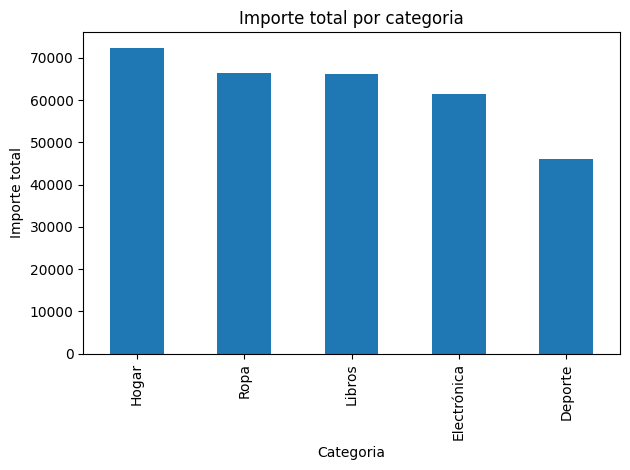

In [16]:
fig, ax = plt.subplots()
resumen_categoria['sum'].plot(kind='bar', ax=ax)
ax.set_xlabel('Categoria')
ax.set_ylabel('Importe total')
ax.set_title('Importe total por categoria')
plt.tight_layout()
plt.show()


### 05.B (0.75pt)

Averigua los 5 clientes que más han gastado en total (la suma de la columna `importe`). Crea un gráfico de barras horizontal, mostrando su nombre, ciudad y gasto total.

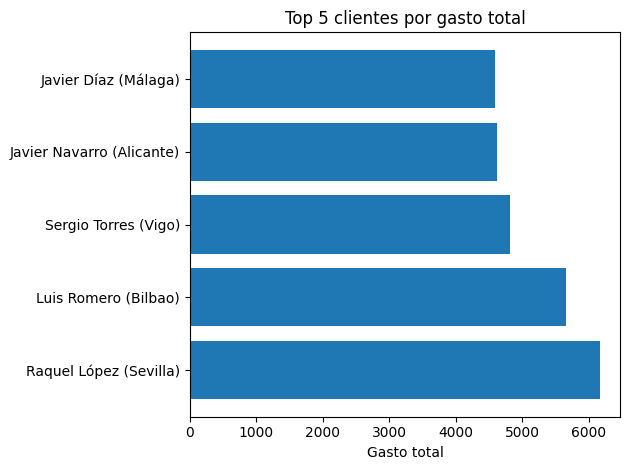

id_cliente  nombre          ciudad  
9           Raquel López    Sevilla     6161.05
67          Luis Romero     Bilbao      5662.21
40          Sergio Torres   Vigo        4808.77
20          Javier Navarro  Alicante    4625.16
72          Javier Díaz     Málaga      4589.63
Name: importe, dtype: float64


In [17]:
top5_clientes = pedidos_validos.groupby(['id_cliente', 'nombre', 'ciudad'])['importe'].sum().sort_values(ascending=False).head(5)

etiquetas = [f"{nombre} ({ciudad})" for _, nombre, ciudad in top5_clientes.index]

fig, ax = plt.subplots()
ax.barh(etiquetas, top5_clientes.values)
ax.set_xlabel('Gasto total')
ax.set_title('Top 5 clientes por gasto total')
plt.tight_layout()
plt.show()

print(top5_clientes)
